# HazeCast SG: Data Cleaning and Feature Selection

**Data team:** Maria and Anu  ·  **Data:** April 2014 to 18 October 2026

A guided tour of how the raw downloads became the table the model learns from. You do not need to
read the code: every step has a short explanation, then the result, then what it tells us.

**Read first:** `01_eda.ipynb` explores the data and explains *why* the choices below were made.

### The Four Layers

| Layer | Its job | Where it lives |
|---|---|---|
| **Raw** | The files exactly as downloaded, never changed | `data/raw/` |
| **Bronze** | Read in, errors fixed | `data/bronze/` |
| **Silver** | One complete hourly clock, short gaps filled, long gaps flagged | `data/silver/` |
| **Gold** | The model table: 56 features per hour | `data/gold/` |

### Contents

1. [Bronze: Errors Fixed](#step1)
2. [Silver: Gaps Found and Filled](#step2)
3. [Quality Checks](#step3)
4. [Gold: The 56 Features](#step4)
5. [Feature Selection: 56 to 36](#step5)
6. [Accuracy Check](#step6)
7. [Feature Lookup](#step7)
8. [Notes for the Model Team](#step8)

To run it, open in JupyterLab from the project folder, then **Run > Run All Cells**
(about 3 minutes). The raw files must be in `data/raw/` first.

In [1]:
# Setup: lets the notebook find the project code. You can skip reading this cell.
import sys, logging, warnings
from pathlib import Path
import pandas as pd
from IPython.display import display

repo_root = Path.cwd()
if not (repo_root / "src" / "hazecast").exists():
    repo_root = repo_root.parent          # notebook was opened from inside notebooks/
sys.path.insert(0, str(repo_root / "src")); sys.path.insert(0, str(repo_root / "notebooks"))
logging.basicConfig(level=logging.ERROR); warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)

from hazecast import data_quality as dq
import data_story_helpers as h
print("Ready.")

Ready.


<a id="step1"></a>
## 1. Bronze: Errors Fixed

We read every raw file and fixed the problems we found while looking at the data.
The rule: **fix what we can prove, remove what cannot be used, never silently guess.**

Each fix lives in the ingest code (`src/hazecast/ingest/`). The table below is produced by
`src/hazecast/data_quality.py`, which counts every fix, so the numbers always match the pipeline.

In [2]:
from hazecast.ingest import pm25 as ip, weather as iw, firms as iff
ip.write_bronze(ip.load_pm25_bronze())
iff.write_bronze(iff.load_firms_bronze())
iw.write_bronze(iw.load_weather_bronze())

fixes = dq.bronze_fixes()
h.style_fixes(fixes)

source,problem,count,action
PM2.5,Rows in the raw file,"110,016",Starting point
PM2.5,Broken timestamp already known (e.g. '2016-04-04 010:00:00'),1,Fixed by hand after checking the rows around it
PM2.5,New broken timestamps,0,Dropped and logged as a warning (never guessed)
PM2.5,Readings that are not numbers,0,"Set to empty, so they cannot be mistaken for real values"
PM2.5,Same hour appears twice with different readings,4,"Kept the first one, logged the rest"
PM2.5,Rows kept,"110,012",Written to data/bronze/pm25.parquet
Fires,Detections in the raw files,"3,784,277",Starting point
Fires,"Not a vegetation fire (volcano, gas flare, other fixed heat source)","150,990",Removed (archive files only: the recent file has no fire-type column)
Fires,"Exact repeat (same place, date and time)","301,783",Removed
Fires,Outside Sumatra and Kalimantan,"1,040,212",Removed: too far away to affect Singapore


* **PM2.5:** one broken timestamp was repaired by hand after checking its neighbours, and 3 hours that
  appeared twice kept their first reading. Any *new* broken timestamp is dropped and logged, never guessed.
* **Fires:** about 40% of detections were removed. Most were too far away to affect Singapore. About
  300,000 were exact repeats, because two recent downloads overlap from August to September 2026.
  About 150,000 were volcanoes or gas flares, not vegetation fires.
* **Weather:** Singapore came as two files (2014 to 2018 and 2019 onwards), and every place has an extra
  August to October 2026 update file. All are joined into one series per place, each file matched to its
  place by the coordinates inside it, not by its name.

<a id="step2"></a>
## 2. Silver: Gaps Found and Filled

Silver puts every source on a **complete clock**: every hour for PM2.5 and weather, every day for fires.
A missing hour now shows up as an empty row instead of quietly disappearing. Then:

* **Short gaps (up to 3 hours)** are filled with a straight line between the readings either side.
  Wind direction is carried forward instead, because averaging 359° and 1° would give 180°.
  Every filled hour is marked in a `filled` column.
* **Longer gaps are left empty** on purpose: guessing across a long gap could invent or erase a haze episode.
* **Fires are never filled.** If the satellite reports zero fires for 5 or more days in a row, that is
  almost certainly a satellite gap, not a fire-free week, so those days are **flagged**.

In [3]:
from hazecast import bronze_to_silver as b2s
pm25_s = b2s.pm25_silver();          b2s.write_silver(pm25_s, "pm25")
weather_s = b2s.weather_silver();    b2s.write_silver(weather_s, "weather")
firms_s = b2s.firms_daily_silver();  b2s.write_silver(firms_s, "firms_daily")

h.style_gaps(dq.silver_gaps(pm25_s, weather_s, firms_s))

source,expected,missing,filled,left_empty,flagged,note
PM2.5,"110,015",3,3,0,0,Gaps of up to 3 hours filled from the readings either side
Weather: Palangka,"109,968",0,0,0,0,Same rule as PM2.5
Weather: Palembang,"109,968",0,0,0,0,Same rule as PM2.5
Weather: Pontianak,"109,968",0,0,0,0,Same rule as PM2.5
Weather: Riau,"109,968",0,0,0,0,Same rule as PM2.5
Weather: Singapore,"109,968",0,0,0,0,Same rule as PM2.5
Fires (days),"4,672",73,0,0,73,"5+ days in a row with zero fires: flagged as a likely satellite gap, never filled"


In [4]:
# The 3 PM2.5 hours that were filled, with the readings around them
filled_at = pm25_s.index[pm25_s["filled"]]
around = sorted({i + k for i in filled_at for k in (-1, 0, 1)})
pm25_s.loc[around, ["ts", "north", "south", "east", "west", "central", "filled"]]

,ts,north,south,east,west,central,filled
16954,2016-03-07 11:00:00,14.0,8.0,12.0,8.0,10.0,False
16955,2016-03-07 12:00:00,11.0,7.5,13.0,9.5,11.0,True
16956,2016-03-07 13:00:00,8.0,7.0,14.0,11.0,12.0,False
35638,2018-04-24 23:00:00,32.0,24.0,19.0,12.0,17.0,False
35639,2018-04-25 00:00:00,27.5,25.0,17.0,12.5,21.0,True
35640,2018-04-25 01:00:00,23.0,26.0,15.0,13.0,25.0,False
38353,2018-08-16 02:00:00,21.0,34.0,20.0,11.0,22.0,False
38354,2018-08-16 03:00:00,20.0,34.0,21.5,16.0,23.0,True
38355,2018-08-16 04:00:00,19.0,34.0,23.0,21.0,24.0,False


the data was in very good shape. Only **3 PM2.5 hours** were missing, each a single
hour next to one of the duplicated timestamps from Step 1, and all were filled. No weather was missing.
**73 fire days** are flagged as likely satellite gaps (in 2022, 2024 and 2026), and the model can see
that flag through the `fire_data_gap_recent` feature.

<a id="step3"></a>
## 3. Quality Checks

In [5]:
h.style_checks(dq.quality_checks(pm25_s, weather_s, firms_s))

check,result,detail
PM2.5: every hour has a reading,Pass,"0 of 110,015 hours still empty after filling"
PM2.5: no negative readings,Pass,0 negative values
PM2.5: highest reading is believable,Pass,Highest hourly reading = 471 µg/m³ (2015 haze)
Weather: every hour present at all 5 places,Pass,0 empty values
Weather: wind direction between 0 and 360,Pass,0 values outside
Weather: no negative rain,Pass,0 values below zero
Fires: suspicious zero-fire stretches flagged,Pass,73 days flagged as likely satellite gaps


every check passed, so silver is safe to build features from.
These checks run again whenever `python -m hazecast.data_quality` is run.

<a id="step4"></a>
## 4. Gold: The 56 Features

Gold is the final table: **one row per hour**, with the inputs (features) the model can use and the
answer it should learn to predict (the PM2.5 reading in the future, called the **label**).

An important rule: **a feature may only use information we would really have at that hour.**
For example, satellites only finish reporting a day's fires after the day ends, so every hour of
today uses *yesterday's* complete fire count. This stops the model from "cheating" by seeing the future.

In [6]:
from hazecast.silver_to_gold import build_gold_hourly, write_gold_hourly
gold = build_gold_hourly(pm25_s, weather_s, firms_s)
write_gold_hourly(gold)

fr = h.load_feature_reduction(repo_root)
features = fr.feature_columns(gold)
print(f"Gold table: {len(gold):,} hours x {len(features)} features")
h.feature_group_table(features)

Gold table: 110,015 hours x 56 features


,group,what it means,number of features
0,Fire hotspots,"how many fires, today and over recent days",22
1,Weather,wind and rain at Singapore and 4 places near the fires,25
2,Wind blowing smoke our way,fires multiplied by how much the wind points at Singapore,3
3,PM2.5 right now,the current reading in each region,6


**How to read the feature names:**

| Part of the name | Meaning | Example |
|---|---|---|
| `lag0`, `lag1`, `lag2`, `lag3` | fires on that day, 1, 2 or 3 days back | `fire_sumatra_lag2` |
| `roll3`, `roll7` | total fires over the last 3 or 7 days | `fire_kalimantan_roll7` |
| `log_lag0` | today's fires on a squashed scale | `fire_total_log_lag0` |
| `roll3h`, `roll24h` | total rain over the last 3 or 24 hours | `rain_riau_roll24h` |
| `now_` | the PM2.5 reading this hour | `now_west` |

<a id="step5"></a>
## 5. Feature Selection: 56 to 36

**Why cut at all?** More inputs is not always better. Many of the 56 say the same thing twice.
Repeated inputs make the model slower, harder to explain, and more likely to learn noise.

We cut in **4 stages**, from the most obvious reason to the most subtle.
To keep the test fair, we chose features **using only data outside the haze seasons** (2015, 2019, and 2026 so far).
2015 and 2019 are used for the final check in Step 6, and 2026 is saved for a future test,
like keeping exam questions hidden while studying.

In [7]:
# Runs the 4 stages. Takes about 1 to 2 minutes.
audit = fr.select_features(gold, corr_threshold=0.90, max_missing=0.20, seed=42)
summary = (audit.assign(stage=audit["reason"].fillna("").str.extract(r"^(stage \d)")[0].fillna("kept"))
                .groupby("stage").size().rename("features"))
summary

stage
kept       36
stage 1    13
stage 3     6
stage 4     1
Name: features, dtype: int64

### Stage 1: Obvious Repeats

**Totals.** `fire_total_lag0` is just `fire_sumatra_lag0 + fire_kalimantan_lag0`.
Here is the proof, on real rows:

In [8]:
check = gold[["fire_sumatra_lag0", "fire_kalimantan_lag0", "fire_total_lag0"]].dropna().tail(5).copy()
check["sumatra + kalimantan"] = check["fire_sumatra_lag0"] + check["fire_kalimantan_lag0"]
display(check)
diff = (gold["fire_total_lag0"] - gold["fire_sumatra_lag0"] - gold["fire_kalimantan_lag0"]).abs().max()
print(f"Biggest difference across all {len(gold):,} rows: {diff}")

,fire_sumatra_lag0,fire_kalimantan_lag0,fire_total_lag0,sumatra + kalimantan
109962,1566.0,1905.0,3471.0,3471.0
109963,1566.0,1905.0,3471.0,3471.0
109964,1566.0,1905.0,3471.0,3471.0
109965,1566.0,1905.0,3471.0,3471.0
109966,1566.0,1905.0,3471.0,3471.0


Biggest difference across all 110,015 rows: 0.0


the total adds nothing new, so all 7 `fire_total_*` features and
`upwind_total` are dropped. The model still sees both parts.

**Wind direction.** Wind direction is stored in compass degrees. That is a problem for the model:

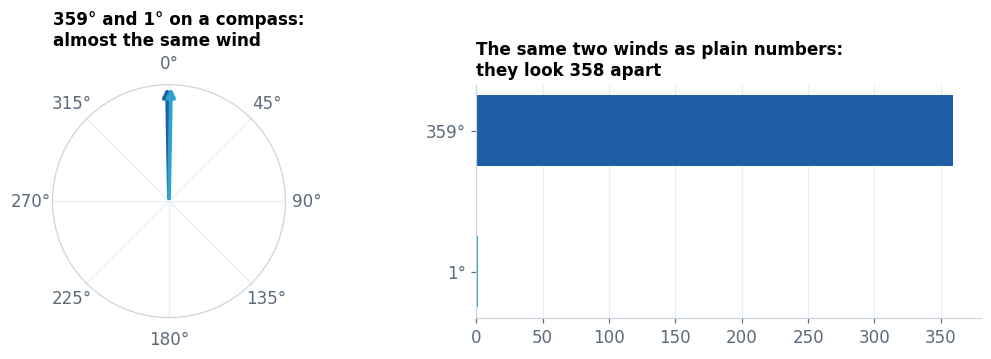

In [9]:
h.show_compass_problem()

to a model, 359 and 1 look far apart, even though they are almost the same wind.
So the 5 raw `wind_dir_*` features are dropped. Wind direction is **not lost**: the `upwind_*`
features already turn it into something meaningful ("how much is the wind blowing from the fires
towards us").

### Stage 2: Gaps or No Change

A feature that is mostly empty, or always the same value, cannot teach the model anything.

In [10]:
print(f"Most-empty feature is {audit['missing_rate'].max():.2%} empty. Limit was 20%.")
print("Dropped at this stage:", int(audit['reason'].fillna('').str.startswith('stage 2').sum()))

Most-empty feature is 0.00% empty. Limit was 20%.
Dropped at this stage: 0


the data is in good shape. Nothing was dropped here.

### Stage 3: Near-Copies

Some features are not exact copies but move almost perfectly together. The chart below shows how
closely each pair of Sumatra fire features moves (1.00 means identical).
When two features score above **0.90**, we keep the one that is more closely linked to PM2.5
and drop the other.

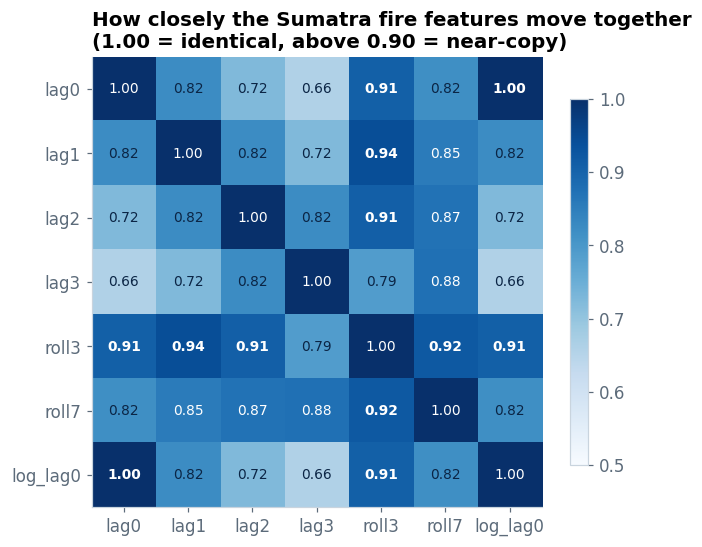

feature,reason
fire_sumatra_lag1,stage 3: near-duplicate of fire_sumatra_roll3 (|r| = 0.93)
fire_sumatra_roll7,stage 3: near-duplicate of fire_sumatra_roll3 (|r| = 0.91)
fire_sumatra_log_lag0,stage 3: near-duplicate of fire_sumatra_lag0 (|r| = 1.00)
fire_kalimantan_lag1,stage 3: near-duplicate of fire_kalimantan_roll3 (|r| = 0.91)
fire_kalimantan_roll7,stage 3: near-duplicate of fire_kalimantan_roll3 (|r| = 0.91)
fire_kalimantan_log_lag0,stage 3: near-duplicate of fire_kalimantan_lag0 (|r| = 1.00)


In [11]:
h.plot_twin_heatmap(gold, "sumatra")
audit.loc[audit["reason"].fillna("").str.startswith("stage 3"), ["feature", "reason"]].style.hide(axis="index")

`log_lag0` scores 1.00 with `lag0` (it is the same number, just squashed).
Yesterday's count (`lag1`) and the 7-day total (`roll7`) move almost exactly like the 3-day total
(`roll3`). One of each pair is enough.

### Stage 4: Does It Help?

For each remaining feature, we **scramble** its values and see how much worse the forecast gets.
If scrambling it changes nothing, the model was not really using it.
We repeat this in 4 different time periods (10 scrambles each, so the result does not depend on luck)
and only drop a feature if it **did not help in any of them**.
This protects features that only matter sometimes, like fires during a smoky month.

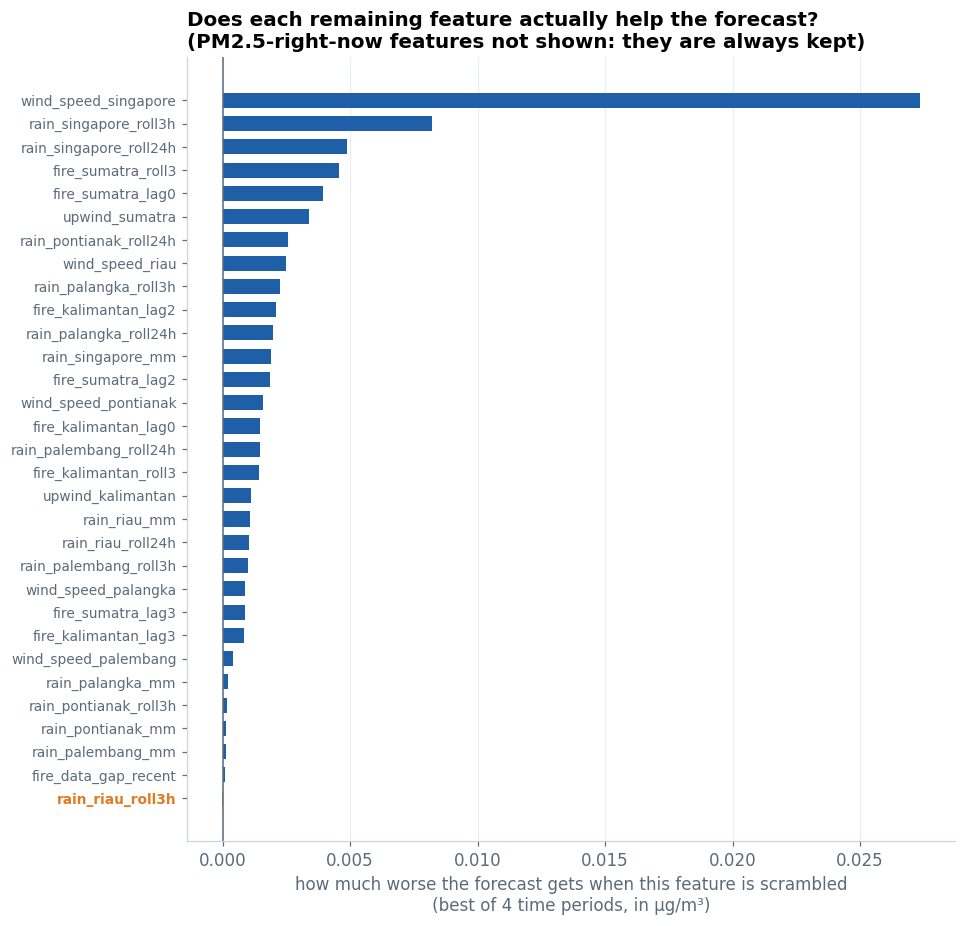

In [12]:
h.plot_usefulness(audit)

almost every remaining feature helped in at least one period. Only
**`rain_riau_roll3h`** (highlighted) never did: Riau's hourly rain and its 24-hour total already carry
the same information, so it is dropped.

### All 56 at a Glance

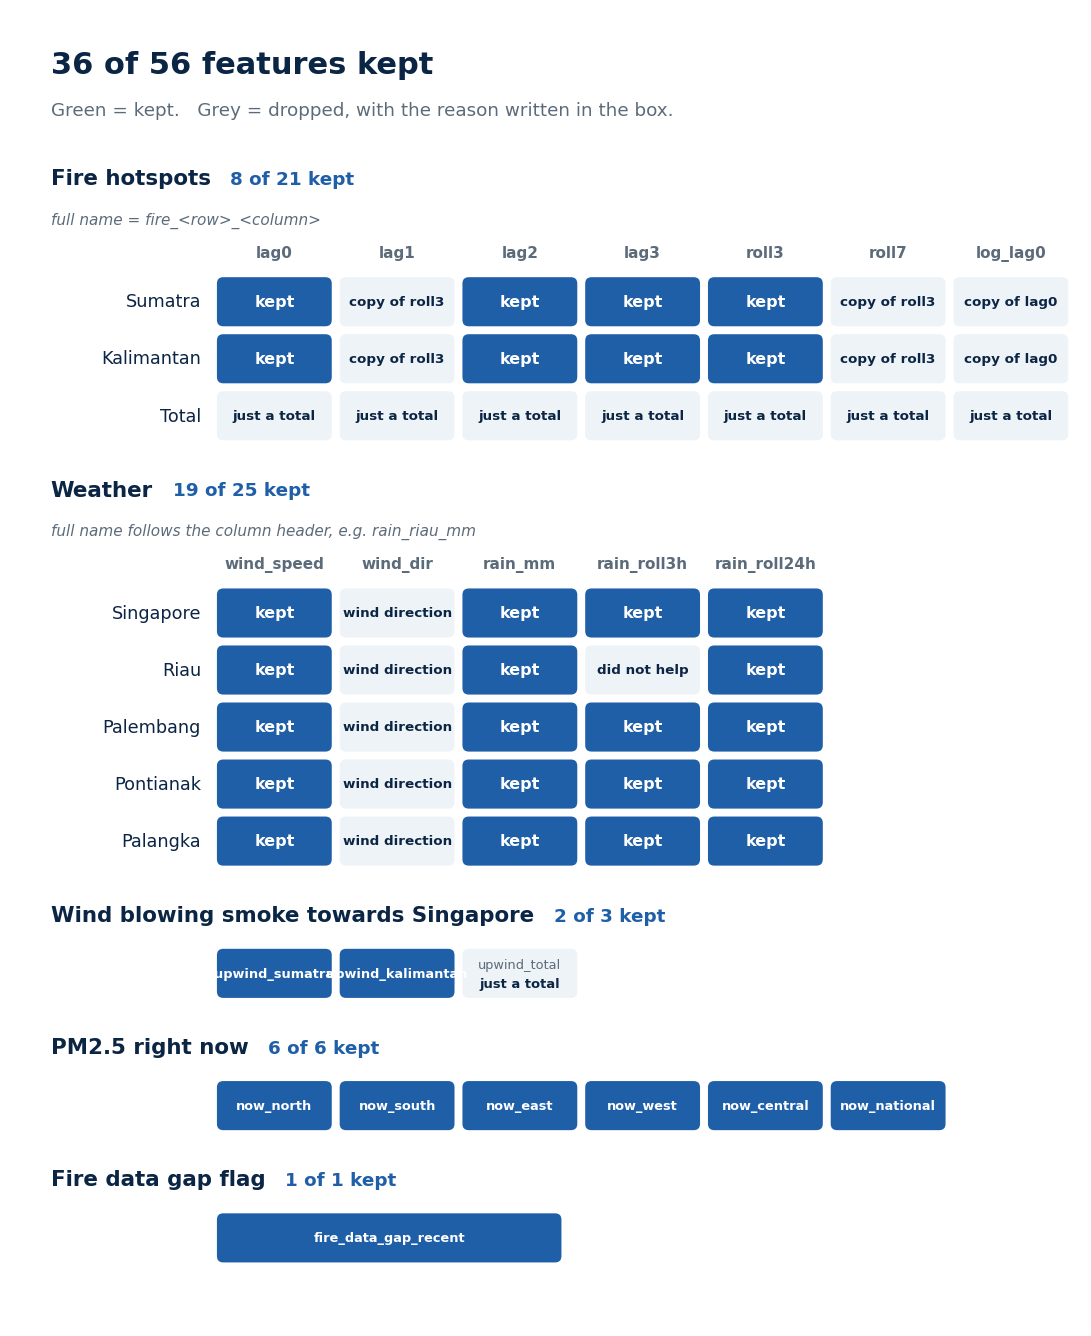

In [13]:
h.plot_feature_map(audit, "hourly")

we kept 36. Every "PM2.5 right now" feature was protected on purpose,
because the current haze level is the strongest clue for the next few hours.

<a id="step6"></a>
## 6. Accuracy Check

This is the most important check. We trained the hourly model twice, once with all 56 features and
once with our 36, and tested both on the **haze seasons kept aside** (2015 and 2019),
forecasting the national PM2.5 reading 1 hour and 6 hours ahead.

This check retrains many models, so it is run as a separate script (about 6 minutes):

```
python experiments/feature_reduction.py --grain hourly --quick
```

Its results are saved in `reports/feature_reduction/`, and we read them here.

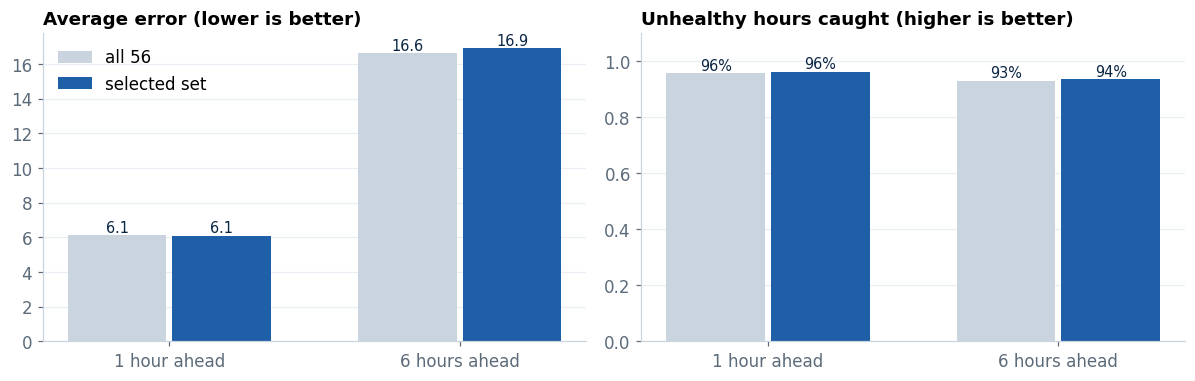

In [14]:
val_path = repo_root / "reports" / "feature_reduction" / "validation_hourly.csv"
if val_path.exists():
    val = pd.read_csv(val_path)
    h.plot_validation(val)
else:
    print("No results yet. Run: python experiments/feature_reduction.py --grain hourly --quick")

with 36 features the forecast is **practically the same**: the average error moves
by less than 0.3 µg/m³ and the share of unhealthy hours caught by less than 1 point. The cut removed
repetition, not information, and the model is simpler to explain.

<a id="step7"></a>
## 7. Feature Lookup

Pick a feature from the list to see what it is, whether it was kept, and why.

In [15]:
h.feature_lookup(audit)

In [16]:
# No dropdown showing (for example on GitHub)? Change the name and run this cell instead.
print(h.explain_feature(audit, "upwind_total"))

upwind_total
  What it is : Fires multiplied by how much the wind blows from them towards Singapore
  Decision   : DROPPED
  Why        : stage 1, rule: exact sum of upwind_sumatra and upwind_kalimantan
  Link to PM2.5 (outside haze seasons, -1 to 1): 0.22


<a id="step8"></a>
## 8. Notes for the Model Team

**How to use the selected features.** Nothing extra to do. Training now uses the 36 features
automatically. The list lives in `src/hazecast/config.py`:

```python
from hazecast.config import SELECTED_FEATURES_HOURLY   # the 36 features
USE_SELECTED_FEATURES = True                           # set False to go back to all 56
```

The gold table itself still has all 56 columns, so nothing is lost if we change our minds.

**Things we found that matter for modelling:**

1. **Haze is rare.** Only 53 days in 12 years went above 56: 31 in 2015 and 17 in the 2026 season so far.
   Average error can look good even when a model misses every haze day, so always check
   *unhealthy hours caught* as well.
2. **The simple guess is hard to beat on average.** "PM2.5 in a few hours = PM2.5 now" has a lower
   average error than the current model. The model wins clearly on catching haze 6 hours ahead.
3. **The tuned model settings** in `config.HOURLY_TUNED_SETTINGS` were tuned on all 56 features.
   They should be re-checked on the 36.
4. **Fire data gaps in 2022, 2024 and 2026** are flagged by `fire_data_gap_recent`. The model can
   see when fire counts are unreliable.
5. **Recent fire data (near real time) cannot filter out non-vegetation fires**, because that file
   has no fire-type column. A small amount of noise in the latest months is expected.
6. **2026 is a live haze season.** It is still running (17 unhealthy days so far, peak 135 on 16 October).
   It was kept out of feature selection so it can become a fair third test season once it ends.
7. **Low-confidence fire detections are currently kept.** A possible next experiment is to drop them
   and see if the forecast improves.